<a href="https://colab.research.google.com/github/Mia-acton/FinalYearProject-RoboSpider-/blob/main/ResQBot_A_Pathfinding_Test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import heapq
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# 0 = empty space, 1 = obstacle
grid = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0, 1, 1, 0],
    [0, 0, 0, 1, 0, 0, 0, 0],
    [1, 1, 0, 1, 1, 1, 0, 1],
    [0, 0, 0, 0, 0, 1, 0, 0],
    [0, 1, 1, 1, 0, 1, 1, 0],
    [0, 0, 0, 1, 0, 0, 0, 0],
    [0, 1, 0, 0, 0, 1, 0, 0]
])

# Positions use (row, column), starting from 0
start = (0, 0)
goal = (7, 7)

print("Map Created!")

Map Created!


In [ ]:
# Estimate distance using horizontal and vertical steps
def heuristic(position, goal):
  return abs(position[0] - goal[0]) + abs(position[1] - goal[1])

def astar(grid, start, goal):
  # Store positions waiting to be explored
  open_list = []
  heapq.heappush(open_list, (heuristic(start, goal), 0, start))

  came_from = {}
  cost_so_far = {start: 0}

  while open_list:
    _, current_cost, current = heapq.heappop(open_list)

    # Skip an entry if a better route was found already
    if current_cost > cost_so_far[current]:
        continue;

    # Rebuild the route when the destination is reached
    if current == goal:
        path = [current]

        while current in came_from:
            current = came_from[current]
            path.append(current)

        return path[::-1]

    # Possible moves: up, down, left and right
    for row_change, col_change in [
        (-1, 0), (1, 0), (0, -1), (0, 1)
    ]:
        neighbour = (
            current[0] + row_change,
            current[1] + col_change
        )

        row, col = neighbour

        # Check that the position is inside the map
        if not (0 <= row < grid.shape[0]
                and 0 <= col < grid.shape[1]):
            continue

        # Skip obstacles
        if grid[row, col] == 1:
            continue

        new_cost = current_cost + 1

        if (neighbour not in cost_so_far
                or new_cost < cost_so_far[neighbour]):

            cost_so_far[neighbour] = new_cost
            priority = new_cost + heuristic(neighbour, goal)

            heapq.heappush(
                open_list, (priority, new_cost, neighbour)
            )

            came_from[neighbour] = current

  return None

Route found!
Number of moves: 14


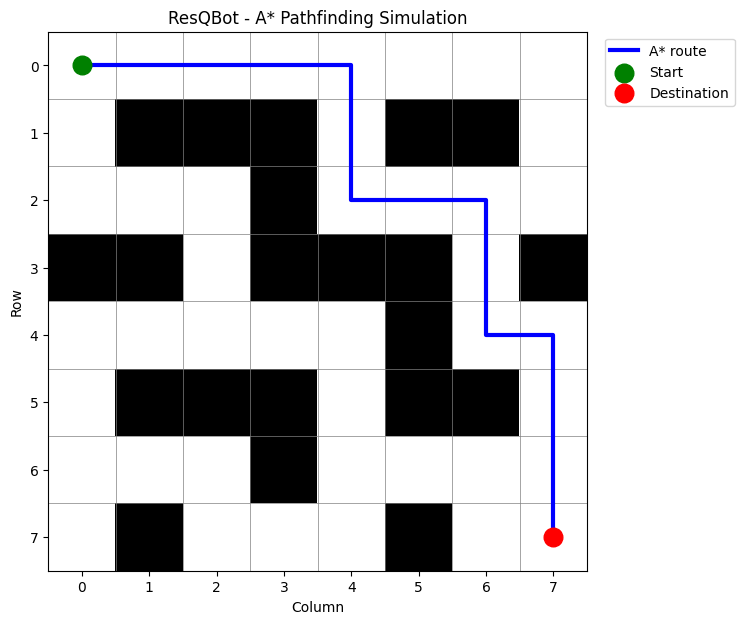

In [ ]:
path = astar(grid, start, goal)

fig, ax = plt.subplots(figsize=(7, 7))

# White = clear space, black = obstacle
ax.imshow(grid, cmap=ListedColormap(["white", "black"]))

if path is not None:
    rows, cols = zip(*path)

    ax.plot(cols, rows, color="blue", linewidth=3, label="A* route")
    print("Route found!")
    print("Number of moves:", len(path) - 1)
else:
  print("No route found - the destination is blocked.")

ax.scatter(start[1], start[0], color="green", s=180,
           label="Start", zorder=3)
ax.scatter(goal[1], goal[0], color="red", s=180,
           label="Destination", zorder=3)

# Draw boundaries around each square
ax.set_xticks(np.arange(-0.5, grid.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-0.5, grid.shape[0], 1), minor=True)
ax.grid(which="minor", color="grey", linewidth=0.5)
ax.tick_params(which="minor", bottom=False, left=False)

ax.set_xlabel("Column")
ax.set_ylabel("Row")
ax.set_title("ResQBot - A* Pathfinding Simulation")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))

plt.show()
